# BÀI THỰC HÀNH SỐ 2 - BÀI 5 (Trang 26–27)
## Phân lớp chẩn đoán bệnh tim — Heart Disease (`heart.csv`)

- **Họ tên sinh viên:** `Nguyễn Phạm Bảo Khanh`
- **MSSV:** `6451071033`
- **Môn học:** Khai phá dữ liệu (Data Mining)
- **Mục tiêu:** Tiền xử lý dữ liệu bệnh tim (`heart.csv`), khảo sát tương quan Pearson và huấn luyện, đánh giá, so sánh 3 mô hình phân lớp (**ID3**, **CART**, **Gaussian Naïve Bayes**) trên thuộc tính quyết định nhị phân `target` (`0`: không bệnh, `1`: có bệnh).

## Thiết lập môi trường & Nạp đường dẫn dữ liệu

In [1]:
import os
import sys
import subprocess

STUDENT_NAME = "Nguyễn Phạm Bảo Khanh"
MSSV = "6451071033"
print(f"{STUDENT_NAME} - {MSSV}")

DATASET_DRIVE_URL = "https://drive.google.com/drive/folders/1KK--zL3h4hWrfIl--FIcrww3dLx-epiB?usp=sharing"


def get_dataset_path(filename: str) -> str:
    """Tìm đường dẫn tập dữ liệu cục bộ, trên Google Drive (Colab), hoặc tải bằng gdown."""
    local_path = os.path.join("Dataset", filename)
    if os.path.exists(local_path):
        return local_path

    if "google.colab" in sys.modules:
        from google.colab import drive
        if not os.path.exists("/content/drive/MyDrive"):
            drive.mount("/content/drive")
        colab_path = os.path.join("/content/drive/MyDrive/Dataset", filename)
        if os.path.exists(colab_path):
            return colab_path

    os.makedirs("Dataset", exist_ok=True)
    subprocess.run(
        [sys.executable, "-m", "gdown", "--folder", DATASET_DRIVE_URL, "-O", "Dataset"],
        check=True,
    )
    if not os.path.exists(local_path):
        raise FileNotFoundError(f"Không tìm thấy tệp dữ liệu tại {local_path}")
    return local_path

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

sns.set_style("whitegrid")

data_path = get_dataset_path("heart.csv")
print(f"Đường dẫn dữ liệu: {data_path}")

Nguyễn Phạm Bảo Khanh - 6451071033


Đường dẫn dữ liệu: Dataset\heart.csv


## Câu a): Nhập dữ liệu đầu vào, xóa các dòng trống và đổi tên 14 cột

In [2]:
print(f"{STUDENT_NAME} - {MSSV}")

data = pd.read_csv(data_path)
print(f"Kích thước dữ liệu ban đầu: {data.shape[0]} dòng, {data.shape[1]} cột")
print(f"Tổng số ô bị thiếu (NaN) ban đầu: {int(data.isna().sum().sum())}")

# Xóa các dòng chứa dữ liệu trống (NaN)
data = data.dropna().reset_index(drop=True)
print(f"Kích thước sau khi xóa dòng trống (dropna): {data.shape[0]} dòng, {data.shape[1]} cột")

# Đổi tên 14 cột theo đúng yêu cầu tài liệu thực hành
data.columns = [
    "age",
    "sex",
    "chest_pain_type",
    "resting_blood_pressure",
    "cholesterol",
    "fasting_blood_sugar",
    "rest_ecg",
    "max_heart_rate_achieved",
    "exercise_induced_angina",
    "st_depression",
    "st_slope",
    "num_major_vessels",
    "thalassemia",
    "target",
]

print("\n--- Thông tin cấu trúc dữ liệu sau đổi tên (info()) ---")
data.info()

print("\n--- 5 dòng đầu tiên (head()) ---")
display(data.head())

print("\n--- Phân bố biến mục tiêu 'target' ---")
print(data["target"].value_counts().sort_index())

Nguyễn Phạm Bảo Khanh - 6451071033
Kích thước dữ liệu ban đầu: 303 dòng, 14 cột
Tổng số ô bị thiếu (NaN) ban đầu: 0
Kích thước sau khi xóa dòng trống (dropna): 303 dòng, 14 cột

--- Thông tin cấu trúc dữ liệu sau đổi tên (info()) ---
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      303 non-null    int64  
 1   sex                      303 non-null    int64  
 2   chest_pain_type          303 non-null    int64  
 3   resting_blood_pressure   303 non-null    int64  
 4   cholesterol              303 non-null    int64  
 5   fasting_blood_sugar      303 non-null    int64  
 6   rest_ecg                 303 non-null    int64  
 7   max_heart_rate_achieved  303 non-null    int64  
 8   exercise_induced_angina  303 non-null    int64  
 9   st_depression            303 non-null    float64
 10  st_slope           

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1



--- Phân bố biến mục tiêu 'target' ---
target
0    138
1    165
Name: count, dtype: int64


**Nhận xét Câu a):**
- Tập dữ liệu `heart.csv` gồm **303 dòng và 14 cột** hoàn chỉnh (không có giá trị `NaN`, sau `dropna()` giữ nguyên `303` dòng).
- Đã đổi tên toàn bộ 14 cột sang tên tường minh (`age`, `sex`, `chest_pain_type`, ..., `thalassemia`, `target`).
- Phân bố lớp `target` khá cân bằng: **`0` (không bệnh tim): `138` mẫu (`45.54%`)**, **`1` (có bệnh tim): `165` mẫu (`54.46%`)**.

## Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson

Nguyễn Phạm Bảo Khanh - 6451071033
--- Top 8 cặp thuộc tính có độ tương đồng |r| cao nhất ---


,,Pearson_r
st_depression,st_slope,-0.577537
exercise_induced_angina,target,-0.436757
chest_pain_type,target,0.433798
st_depression,target,-0.430696
max_heart_rate_achieved,target,0.421741
age,max_heart_rate_achieved,-0.398522
chest_pain_type,exercise_induced_angina,-0.394280
num_major_vessels,target,-0.391724


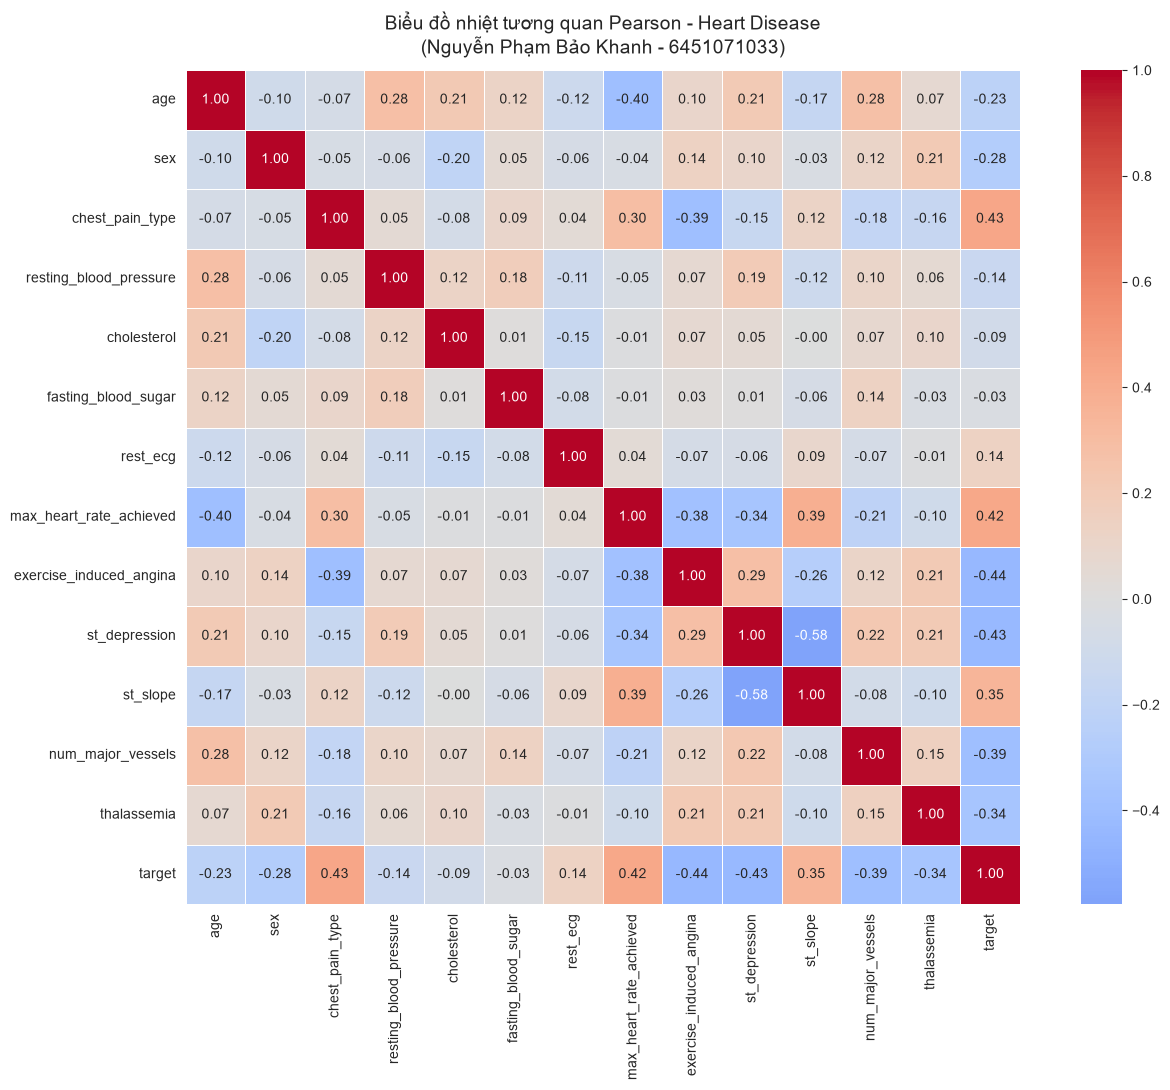

In [3]:
print(f"{STUDENT_NAME} - {MSSV}")

corr_matrix = data.corr(method="pearson")

upper_mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
top_corr = corr_matrix.where(upper_mask).stack().sort_values(key=abs, ascending=False)
print("--- Top 8 cặp thuộc tính có độ tương đồng |r| cao nhất ---")
display(top_corr.head(8).to_frame(name="Pearson_r"))

plt.figure(figsize=(14, 11))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True,
)
plt.title(f"Biểu đồ nhiệt tương quan Pearson - Heart Disease\n({STUDENT_NAME} - {MSSV})", fontsize=14, pad=12)
plt.tight_layout()
plt.show()

**Nhận xét Câu 3:**
- Hệ số tương quan tuyệt đối lớn nhất giữa các cặp thuộc tính là `|r| ≈ 0.578` (`st_depression` và `st_slope`: `-0.58`), hoàn toàn nhỏ hơn ngưỡng `0.7` nên **giữ nguyên toàn bộ 14 cột**, không cần loại bỏ cột nào.
- Các thuộc tính có tương quan đáng kể nhất với `target` gồm `exercise_induced_angina` (`-0.44`), `chest_pain_type` (`+0.43`), `st_depression` (`-0.43`), `max_heart_rate_achieved` (`+0.42`) và `num_major_vessels` (`-0.39`).

## Câu 4: Tách dữ liệu thành thuộc tính đặc trưng (`features`) và thuộc tính quyết định (`labels`)

In [4]:
print(f"{STUDENT_NAME} - {MSSV}")

features = data.drop("target", axis=1)
labels = data["target"]

print(f"Kích thước features: {features.shape}")
print(f"Kích thước labels:   {labels.shape}")
print(f"Danh sách thuộc tính đầu vào ({len(features.columns)} cột): {list(features.columns)}")
display(features.head())

Nguyễn Phạm Bảo Khanh - 6451071033
Kích thước features: (303, 13)
Kích thước labels:   (303,)
Danh sách thuộc tính đầu vào (13 cột): ['age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol', 'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved', 'exercise_induced_angina', 'st_depression', 'st_slope', 'num_major_vessels', 'thalassemia']


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2


**Nhận xét Câu 4:** Đã tách dữ liệu thành `features` (`303 x 13` thuộc tính lâm sàng đầu vào) và `labels` (`303` nhãn `target` nhị phân `0`/`1`).

## Câu 5: Kiểm tra các cột không phải dạng số và chuyển đổi sang dạng one-hot vector

In [5]:
print(f"{STUDENT_NAME} - {MSSV}")

non_numeric_cols = features.select_dtypes(exclude=[np.number]).columns
print(f"Các cột không phải dạng số: {list(non_numeric_cols)} (số lượng: {len(non_numeric_cols)})")

features_onehot = pd.get_dummies(features, columns=non_numeric_cols, dtype=int)
print(f"Kích thước sau pd.get_dummies: {features_onehot.shape}")
display(features_onehot.head())

Nguyễn Phạm Bảo Khanh - 6451071033
Các cột không phải dạng số: [] (số lượng: 0)
Kích thước sau pd.get_dummies: (303, 13)


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2


**Nhận xét Câu 5:** Tất cả **13** thuộc tính trong `heart.csv` đều đã được mã hóa sẵn ở dạng số (`int64` và `float64`), danh sách cột phi số trống nên `pd.get_dummies(..., dtype=int)` giữ nguyên kích thước `(303, 13)`.

## Câu 6: Chia dữ liệu huấn luyện (70%) và kiểm thử (30%)

In [6]:
print(f"{STUDENT_NAME} - {MSSV}")

X_train, X_test, y_train, y_test = train_test_split(
    features_onehot, labels, test_size=0.3, random_state=42
)

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}, y_test:  {y_test.shape}")
print("\nPhân bố nhãn tập huấn luyện (70%):")
print(y_train.value_counts().sort_index())
print("\nPhân bố nhãn tập kiểm thử (30%):")
print(y_test.value_counts().sort_index())

Nguyễn Phạm Bảo Khanh - 6451071033
X_train: (212, 13), y_train: (212,)
X_test:  (91, 13), y_test:  (91,)

Phân bố nhãn tập huấn luyện (70%):
target
0     97
1    115
Name: count, dtype: int64

Phân bố nhãn tập kiểm thử (30%):
target
0    41
1    50
Name: count, dtype: int64


**Nhận xét Câu 6:** Tập dữ liệu được chia theo tỉ lệ `70/30` với `random_state=42`: **`212` mẫu huấn luyện** (`0`: `97`, `1`: `115`) và **`91` mẫu kiểm thử** (`0`: `41`, `1`: `50`).

## Câu 7: Xây dựng cây quyết định ID3 (`criterion='entropy'`) và đánh giá kết quả

Nguyễn Phạm Bảo Khanh - 6451071033
ID3 (Entropy) Accuracy: 0.692308 (69.23%)
Độ sâu toàn cây ID3: 7 | Số nút lá: 33

Báo cáo phân lớp (Classification Report - ID3):
              precision    recall  f1-score   support

           0       0.64      0.71      0.67        41
           1       0.74      0.68      0.71        50

    accuracy                           0.69        91
   macro avg       0.69      0.69      0.69        91
weighted avg       0.70      0.69      0.69        91



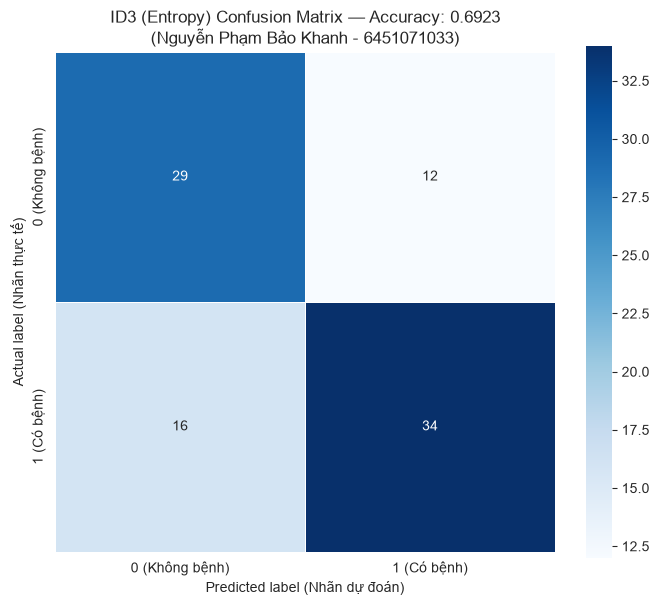

In [7]:
print(f"{STUDENT_NAME} - {MSSV}")

id3_clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=42)
id3_clf.fit(X_train, y_train)
id3_pred = id3_clf.predict(X_test)

id3_score = metrics.accuracy_score(y_test, id3_pred)
print(f"ID3 (Entropy) Accuracy: {id3_score:.6f} ({id3_score * 100:.2f}%)")
print(f"Độ sâu toàn cây ID3: {id3_clf.get_depth()} | Số nút lá: {id3_clf.get_n_leaves()}")
print("\nBáo cáo phân lớp (Classification Report - ID3):")
print(metrics.classification_report(y_test, id3_pred, zero_division=0))

class_labels = [0, 1]
tick_labels = ["0 (Không bệnh)", "1 (Có bệnh)"]
id3_cm = metrics.confusion_matrix(y_test, id3_pred, labels=class_labels)

plt.figure(figsize=(7, 6))
sns.heatmap(
    id3_cm,
    annot=True,
    fmt="d",
    linewidths=0.5,
    square=True,
    cmap="Blues",
    xticklabels=tick_labels,
    yticklabels=tick_labels,
)
plt.ylabel("Actual label (Nhãn thực tế)")
plt.xlabel("Predicted label (Nhãn dự đoán)")
plt.title(f"ID3 (Entropy) Confusion Matrix — Accuracy: {id3_score:.4f}\n({STUDENT_NAME} - {MSSV})", fontsize=12)
plt.tight_layout()
plt.show()

Nguyễn Phạm Bảo Khanh - 6451071033


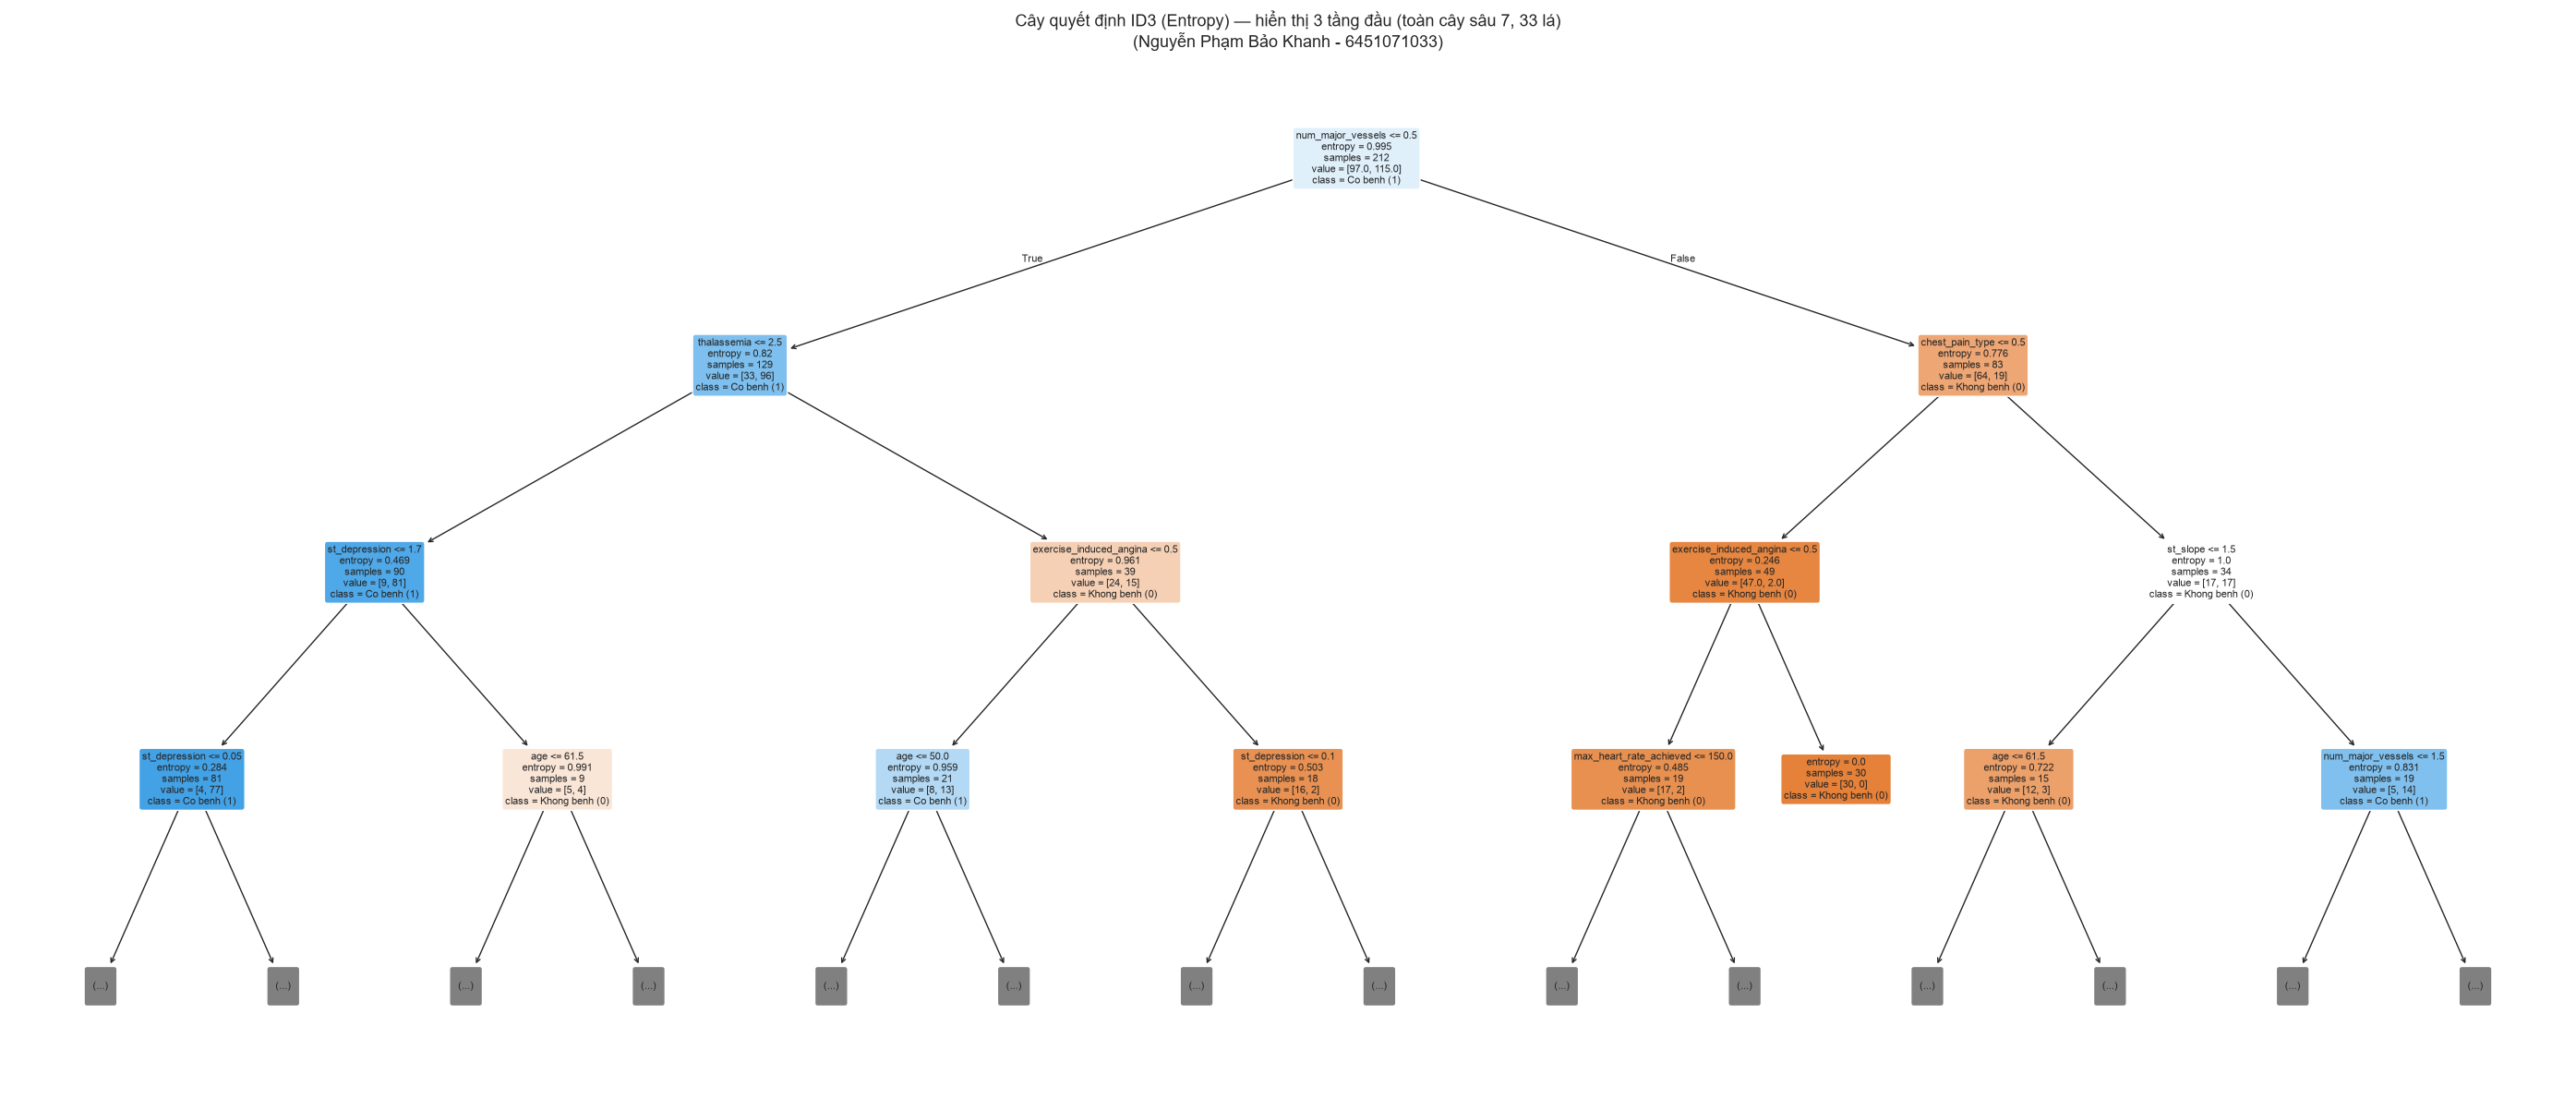

In [8]:
print(f"{STUDENT_NAME} - {MSSV}")

# Cây đầy đủ có độ sâu 7 và 33 nút lá nên hiển thị 3 tầng đầu (max_depth=3) để hình rõ nét
fig, ax = plt.subplots(figsize=(28, 12))
tree.plot_tree(
    id3_clf,
    max_depth=3,
    feature_names=list(features_onehot.columns),
    class_names=["Khong benh (0)", "Co benh (1)"],
    filled=True,
    rounded=True,
    fontsize=8,
    ax=ax,
)
plt.title(
    f"Cây quyết định ID3 (Entropy) — hiển thị 3 tầng đầu (toàn cây sâu {id3_clf.get_depth()}, {id3_clf.get_n_leaves()} lá)\n({STUDENT_NAME} - {MSSV})",
    fontsize=13,
)
plt.tight_layout()
plt.show()

**Nhận xét Câu 7:**
- Mô hình **ID3 (`criterion='entropy'`)** đạt độ chính xác **`69.23%`** (`63/91` mẫu đúng), `Macro F1 = 0.69` (`0`: `0.67`, `1`: `0.71`).
- Trên ma trận nhầm lẫn, mô hình dự đoán đúng `29` ca không bệnh và `34` ca có bệnh, nhưng còn `16` ca âm tính giả (FN — có bệnh bị đoán không bệnh) và `12` ca dương tính giả (FP). Toàn cây có độ sâu `7` và `33` lá.

## Câu 8: Xây dựng cây quyết định CART (`criterion='gini'`) và đánh giá kết quả

Nguyễn Phạm Bảo Khanh - 6451071033
CART (Gini) Accuracy: 0.736264 (73.63%)
Độ sâu toàn cây CART: 9 | Số nút lá: 37

Báo cáo phân lớp (Classification Report - CART):
              precision    recall  f1-score   support

           0       0.68      0.78      0.73        41
           1       0.80      0.70      0.74        50

    accuracy                           0.74        91
   macro avg       0.74      0.74      0.74        91
weighted avg       0.74      0.74      0.74        91



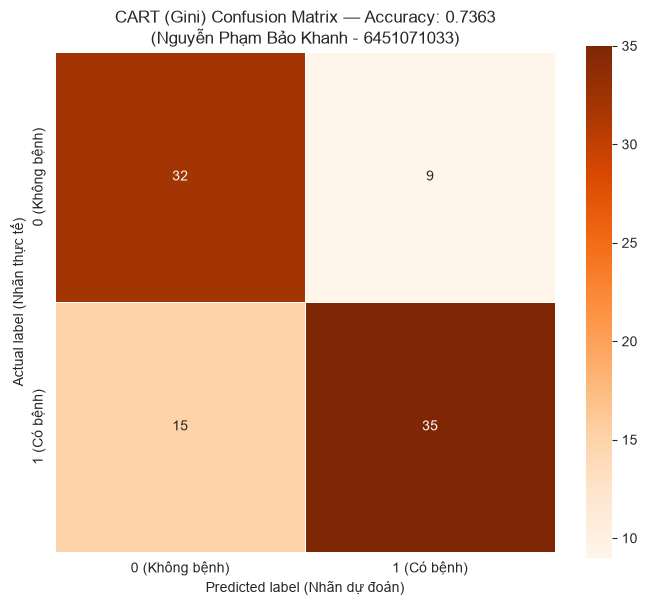

In [9]:
print(f"{STUDENT_NAME} - {MSSV}")

cart_clf = tree.DecisionTreeClassifier(criterion="gini", random_state=42)
cart_clf.fit(X_train, y_train)
cart_pred = cart_clf.predict(X_test)

cart_score = metrics.accuracy_score(y_test, cart_pred)
print(f"CART (Gini) Accuracy: {cart_score:.6f} ({cart_score * 100:.2f}%)")
print(f"Độ sâu toàn cây CART: {cart_clf.get_depth()} | Số nút lá: {cart_clf.get_n_leaves()}")
print("\nBáo cáo phân lớp (Classification Report - CART):")
print(metrics.classification_report(y_test, cart_pred, zero_division=0))

cart_cm = metrics.confusion_matrix(y_test, cart_pred, labels=class_labels)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cart_cm,
    annot=True,
    fmt="d",
    linewidths=0.5,
    square=True,
    cmap="Oranges",
    xticklabels=tick_labels,
    yticklabels=tick_labels,
)
plt.ylabel("Actual label (Nhãn thực tế)")
plt.xlabel("Predicted label (Nhãn dự đoán)")
plt.title(f"CART (Gini) Confusion Matrix — Accuracy: {cart_score:.4f}\n({STUDENT_NAME} - {MSSV})", fontsize=12)
plt.tight_layout()
plt.show()

Nguyễn Phạm Bảo Khanh - 6451071033


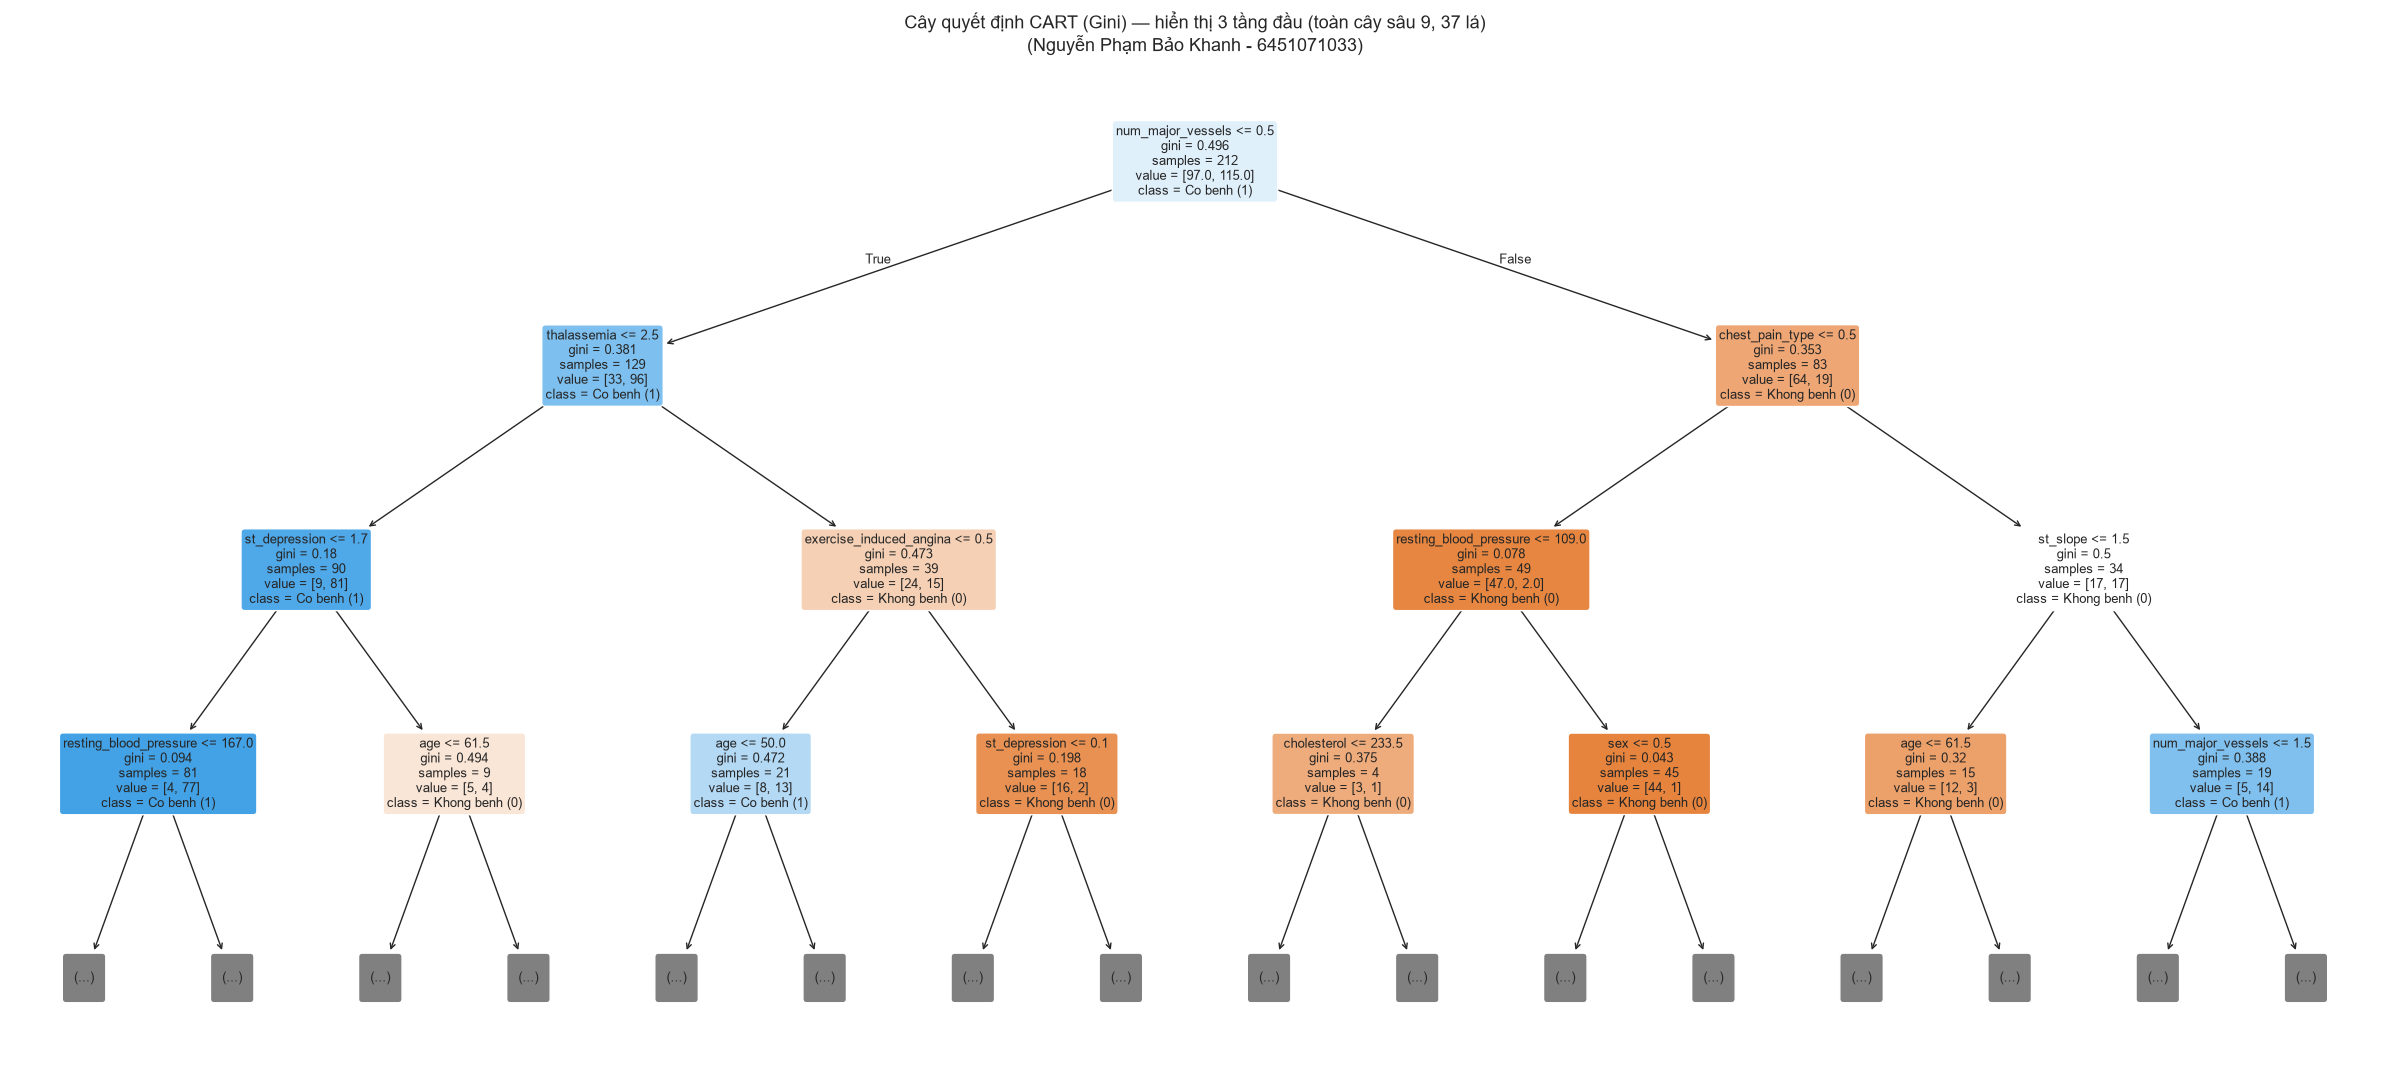

In [10]:
print(f"{STUDENT_NAME} - {MSSV}")

# Cây đầy đủ có độ sâu 9 và 37 nút lá nên hiển thị 3 tầng đầu (max_depth=3) để hình rõ nét
fig, ax = plt.subplots(figsize=(24, 11))
tree.plot_tree(
    cart_clf,
    max_depth=3,
    feature_names=list(features_onehot.columns),
    class_names=["Khong benh (0)", "Co benh (1)"],
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax,
)
plt.title(
    f"Cây quyết định CART (Gini) — hiển thị 3 tầng đầu (toàn cây sâu {cart_clf.get_depth()}, {cart_clf.get_n_leaves()} lá)\n({STUDENT_NAME} - {MSSV})",
    fontsize=13,
)
plt.tight_layout()
plt.show()

**Nhận xét Câu 8:**
- Mô hình **CART (`criterion='gini'`)** đạt độ chính xác **`73.63%`** (`67/91` mẫu đúng), cao hơn ID3 `4.40%` (`Macro F1 = 0.74`, lớp `0`: `0.73`, lớp `1`: `0.74`).
- Số ca dự đoán đúng là `32` (`target=0`) và `35` (`target=1`), giảm được lỗi FP xuống `9` và FN xuống `15`. Toàn cây đạt độ sâu `9` với `37` nút lá.

## Câu 9: Xây dựng mô hình phân lớp Naïve Bayes (`GaussianNB`) và đánh giá kết quả

Nguyễn Phạm Bảo Khanh - 6451071033
GaussianNB Accuracy: 0.835165 (83.52%)

Báo cáo phân lớp (Classification Report - GaussianNB):
              precision    recall  f1-score   support

           0       0.78      0.88      0.83        41
           1       0.89      0.80      0.84        50

    accuracy                           0.84        91
   macro avg       0.84      0.84      0.83        91
weighted avg       0.84      0.84      0.84        91



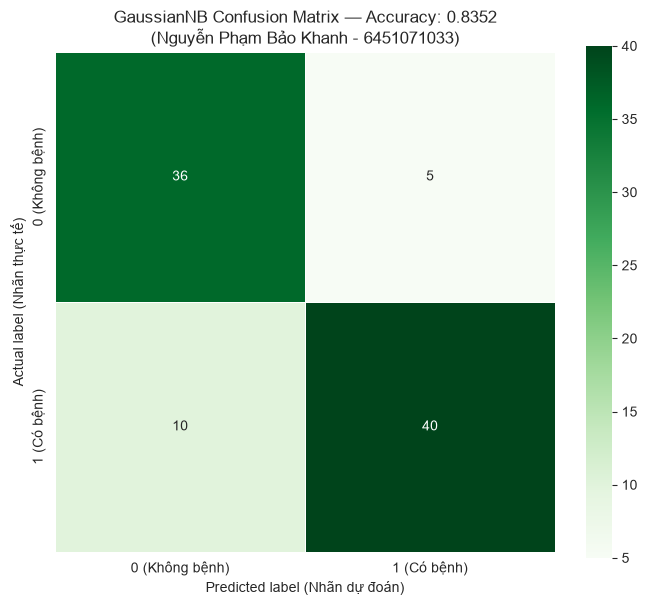

In [11]:
print(f"{STUDENT_NAME} - {MSSV}")

gnb = GaussianNB()
gnb.fit(X_train, y_train)
bayes_pred = gnb.predict(X_test)

bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print(f"GaussianNB Accuracy: {bayes_score:.6f} ({bayes_score * 100:.2f}%)")
print("\nBáo cáo phân lớp (Classification Report - GaussianNB):")
print(metrics.classification_report(y_test, bayes_pred, zero_division=0))

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred, labels=class_labels)

plt.figure(figsize=(7, 6))
sns.heatmap(
    bayes_cm,
    annot=True,
    fmt="d",
    linewidths=0.5,
    square=True,
    cmap="Greens",
    xticklabels=tick_labels,
    yticklabels=tick_labels,
)
plt.ylabel("Actual label (Nhãn thực tế)")
plt.xlabel("Predicted label (Nhãn dự đoán)")
plt.title(f"GaussianNB Confusion Matrix — Accuracy: {bayes_score:.4f}\n({STUDENT_NAME} - {MSSV})", fontsize=12)
plt.tight_layout()
plt.show()

**Nhận xét Câu 9:**
- Mô hình **Naïve Bayes (`GaussianNB`)** đạt độ chính xác rất ấn tượng là **`83.52%`** (`76/91` mẫu đúng), vượt trội rõ rệt so với cả ID3 và CART.
- Cả hai lớp đều đạt F1 cao và cân đối: lớp `0` (`F1 = 0.83`, recall `0.88`) và lớp `1` (`F1 = 0.84`, precision `0.89`, recall `0.80`), giảm đáng kể cả FP (`5`) lẫn FN (`10`).

## Câu 10: So sánh kết quả của các mô hình

Nguyễn Phạm Bảo Khanh - 6451071033
--- Bảng tổng hợp so sánh các mô hình (Heart Disease) ---


,Mô hình,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro),F1-score (Weighted),Recall lớp 1 (Có bệnh)
0,ID3 (Entropy),0.6923,0.6918,0.6937,0.6914,0.6931,0.68
1,CART (Gini),0.7363,0.7382,0.7402,0.7360,0.7368,0.70
2,Naïve Bayes (GaussianNB),0.8352,0.8357,0.8390,0.8348,0.8356,0.80


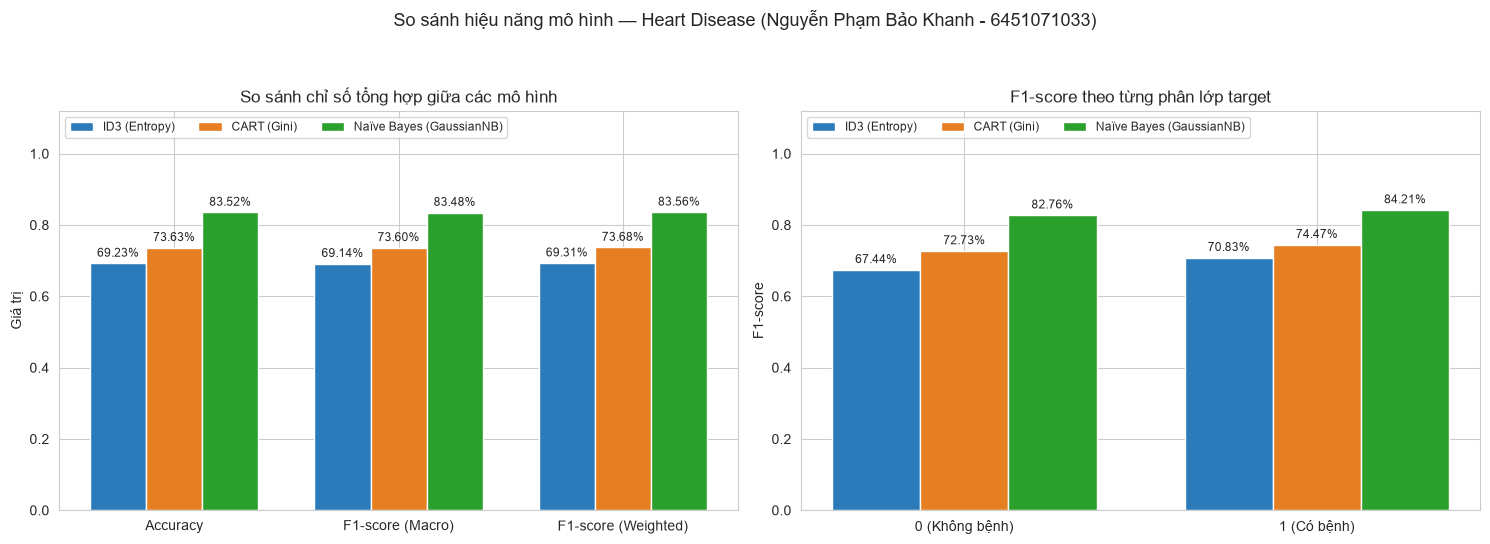

In [12]:
print(f"{STUDENT_NAME} - {MSSV}")

models_preds = [
    ("ID3 (Entropy)", id3_pred),
    ("CART (Gini)", cart_pred),
    ("Naïve Bayes (GaussianNB)", bayes_pred),
]

summary_rows = []
class_f1_rows = {}
for name, pred in models_preds:
    f1_per_cls = metrics.f1_score(y_test, pred, labels=class_labels, average=None, zero_division=0)
    summary_rows.append({
        "Mô hình": name,
        "Accuracy": metrics.accuracy_score(y_test, pred),
        "Precision (Macro)": metrics.precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (Macro)": metrics.recall_score(y_test, pred, average="macro", zero_division=0),
        "F1-score (Macro)": metrics.f1_score(y_test, pred, average="macro", zero_division=0),
        "F1-score (Weighted)": metrics.f1_score(y_test, pred, average="weighted", zero_division=0),
        "Recall lớp 1 (Có bệnh)": metrics.recall_score(y_test, pred, pos_label=1, zero_division=0),
    })
    class_f1_rows[name] = f1_per_cls

comparison_df = pd.DataFrame(summary_rows)
print("--- Bảng tổng hợp so sánh các mô hình (Heart Disease) ---")
display(comparison_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
colors = ["#2b7bba", "#e67e22", "#2ca02c"]

# Biểu đồ 1: Chỉ số tổng hợp
metric_cols = ["Accuracy", "F1-score (Macro)", "F1-score (Weighted)"]
x = np.arange(len(metric_cols))
width = 0.25

for idx, (_, row) in enumerate(comparison_df.iterrows()):
    vals = [row[m] for m in metric_cols]
    bars = axes[0].bar(x + (idx - 1) * width, vals, width, label=row["Mô hình"], color=colors[idx])
    for bar in bars:
        h = bar.get_height()
        axes[0].annotate(f"{h:.2%}", (bar.get_x() + bar.get_width() / 2, h),
                         ha="center", va="bottom", fontsize=8.5, xytext=(0, 3), textcoords="offset points")

axes[0].set_xticks(x)
axes[0].set_xticklabels(metric_cols)
axes[0].set_ylim(0, 1.12)
axes[0].set_ylabel("Giá trị")
axes[0].set_title("So sánh chỉ số tổng hợp giữa các mô hình")
axes[0].legend(loc="upper left", ncol=3, fontsize=8.5)

# Biểu đồ 2: F1-score theo từng lớp (0 vs 1)
x_cls = np.arange(len(class_labels))
for idx, (name, _) in enumerate(models_preds):
    vals = class_f1_rows[name]
    bars = axes[1].bar(x_cls + (idx - 1) * width, vals, width, label=name, color=colors[idx])
    for bar in bars:
        h = bar.get_height()
        axes[1].annotate(f"{h:.2%}", (bar.get_x() + bar.get_width() / 2, h),
                         ha="center", va="bottom", fontsize=8.5, xytext=(0, 3), textcoords="offset points")

axes[1].set_xticks(x_cls)
axes[1].set_xticklabels(tick_labels)
axes[1].set_ylim(0, 1.12)
axes[1].set_ylabel("F1-score")
axes[1].set_title("F1-score theo từng phân lớp target")
axes[1].legend(loc="upper left", ncol=3, fontsize=8.5)

fig.suptitle(f"So sánh hiệu năng mô hình — Heart Disease ({STUDENT_NAME} - {MSSV})", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

**Nhận xét & Kết luận Câu 10 (Bài 5 - Heart Disease):**
1. **Xếp hạng hiệu năng:** Trên tập `heart.csv` (`212` huấn luyện / `91` kiểm thử), **Naïve Bayes (`GaussianNB`)** đạt hiệu năng vượt trội với **`Accuracy = 83.52%`**, `Macro F1 = 0.8348`, tiếp theo là **CART (`Gini`)** đạt **`73.63%`** (`Macro F1 = 0.7360`) và **ID3 (`Entropy`)** đạt **`69.23%`** (`Macro F1 = 0.6914`).
2. **Vì sao `GaussianNB` vượt trội trên tập dữ liệu bệnh tim:**
   - **Kích thước dữ liệu nhỏ (`212` mẫu huấn luyện, `13` thuộc tính):** Các cây quyết định không cắt tỉa (`depth = 7–9`, `33–37` lá) dễ học thuộc nhiễu cục bộ trên tập huấn luyện nhỏ (overfitting), làm giảm khả năng tổng quát trên `91` mẫu kiểm thử.
   - **Tương quan chéo giữa các đặc trưng thấp (`max |r| ≈ 0.578`):** Giả định độc lập có điều kiện của Naïve Bayes hoạt động ổn định và tổng hợp đồng thời thông tin từ toàn bộ 13 chỉ số y khoa (như `chest_pain_type`, `max_heart_rate_achieved`, `st_depression`, `exercise_induced_angina`, `num_major_vessels`) với phương sai thấp.
3. **Ý nghĩa thực tiễn y khoa:** Ở bài toán phát hiện bệnh tim (`target=1`), hạn chế âm tính giả (FN — bỏ sót bệnh nhân có bệnh) là cực kỳ quan trọng. `GaussianNB` giảm số ca FN xuống còn **`10`** (`Recall lớp 1 = 80%`), cải thiện rõ rệt so với `CART` (`FN = 15`, `Recall = 70%`) và `ID3` (`FN = 16`, `Recall = 68%`).